# 멀티모달 RAG 실행 노트북

핵심 로직은 `src/` 의 파이썬 모듈에 있고, 이 노트북은 **단계별로 호출하고 결과를 남기는 용도**입니다.

```
PDF ─▶ [1 추출 extract.py] ─▶ [2 요약 summarize.py] ─▶ [3 검색·생성 retriever.py] ─▶ 답변
```

대상 PDF: `data/education_test.pdf` (초등학교 취학 나이가 학업성취도에 미치는 영향 — 한국어 논문)

In [1]:
import sys, pickle
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from IPython.display import Image, display
import extract, summarize, retriever

print('PDF       :', extract.PDF_NAME, '| 존재:', (extract.DATA_DIR / extract.PDF_NAME).exists())
print('API 키 설정:', (summarize.check_api_key() or True))  # 값은 출력하지 않음

PDF       : education_test.pdf | 존재: True
API 키 설정: True


## 1단계. 데이터 추출 (텍스트 · 표 · 이미지)
`partition_pdf(strategy='hi_res')` 로 레이아웃을 분석해 세 종류로 분리하고, 그림은 `data/figures/` 에 저장합니다. (약 2~3분)

In [2]:
extract.run()

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1


No languages specified, defaulting to English.


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Loading weights:  46%|████▌     | 169/367 [00:00<00:00, 1662.44it/s]

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 2807.28it/s]

추출 완료 — 140.0초, 전체 요소 30개
텍스트 블록 수: 20
표 블록 수    : 10
  CompositeElement      : 20개
  Table                 : 10개
추출된 이미지: 22 개
분할 후 블록 수: 35
저장 완료: C:\workspaces\chatbot\multimodal-rag\multimodel_rag\data\extracted.pkl


figures/ 이미지: 22 개
figure-13-5.jpg


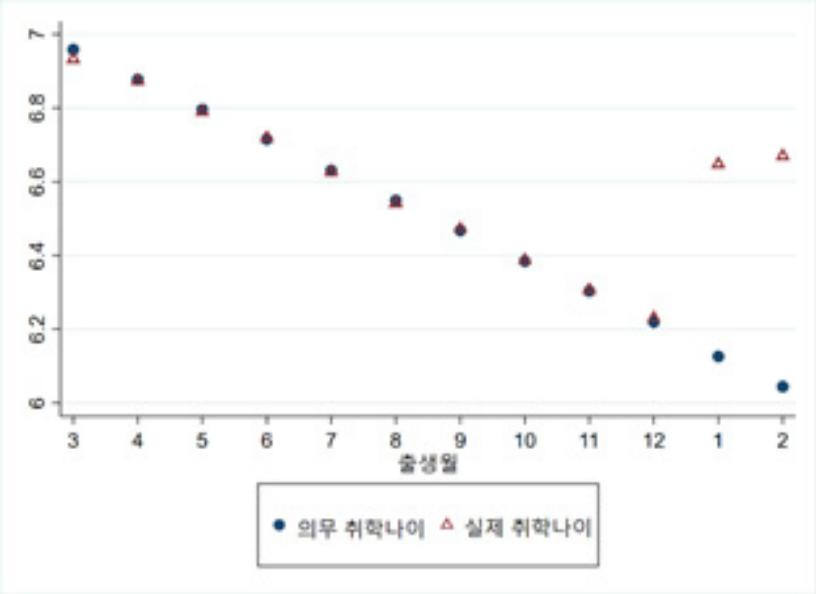

figure-18-18.jpg


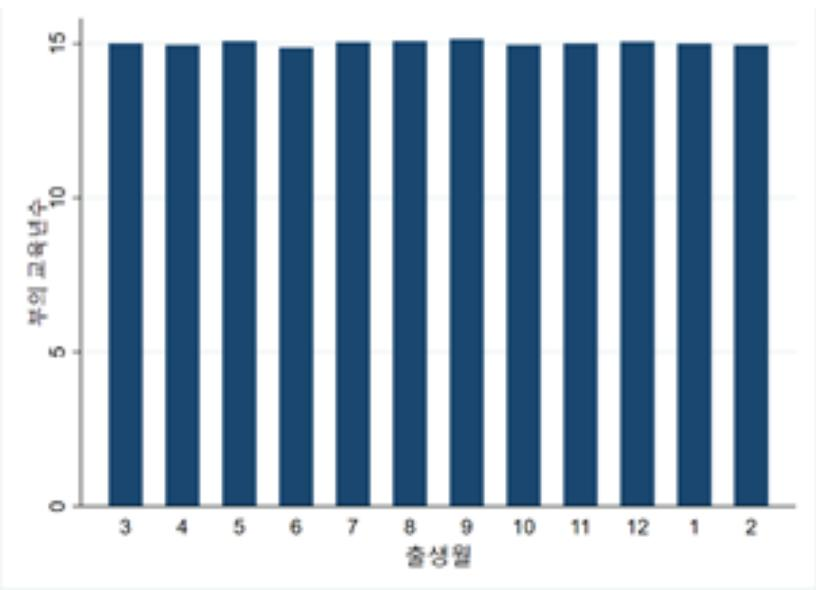

In [3]:
figs = sorted(extract.FIGURES_DIR.glob('*.jpg'))
print('figures/ 이미지:', len(figs), '개')
for f in [p for p in figs if p.name in ('figure-13-5.jpg', 'figure-18-18.jpg')]:
    print(f.name)
    display(Image(filename=str(f), width=420))

## 2단계. 요약 생성
텍스트·표·이미지를 각각 한국어 요약으로 만듭니다. 이 요약이 **검색용 색인**이 됩니다.

In [4]:
summarize.run()

texts_2k_token 35개 / tables 10개


텍스트·표 요약 완료 — 87.1초 (텍스트 35, 표 10)


이미지 요약 완료 — 33.0초 (22장)

[텍스트 요약 예시]
 초등학교 취학 나이가 학업성취도에 미치는 영향을 분석한 연구로, 취학 나이가 실제로 학업 성적에 미치는 인과적 효과를 추정하였다. 도구변수를 사용한 결과, 취학 나이가 많은 학생들이 국어, 수학, 영어 성적이 더 높은 것으로 나타났으며, 고등학교에서도 긍정적인 효과가 관찰되었다. 이는 어린 학생들의 학습과 적응을 지원할 정책의 필요성을 시사한다.

[이미지 요약 예시]
 막대 그래프가 포함된 이미지로, 300에서 500 사이의 데이터를 나타내고 있으며, 여러 항목의 값이 비교되고 있습니다.
저장 완료: C:\workspaces\chatbot\multimodal-rag\multimodel_rag\data\summaries.pkl


텍스트 요약 35 / 표 요약 10 / 이미지 요약 22
figure-12-1.jpg


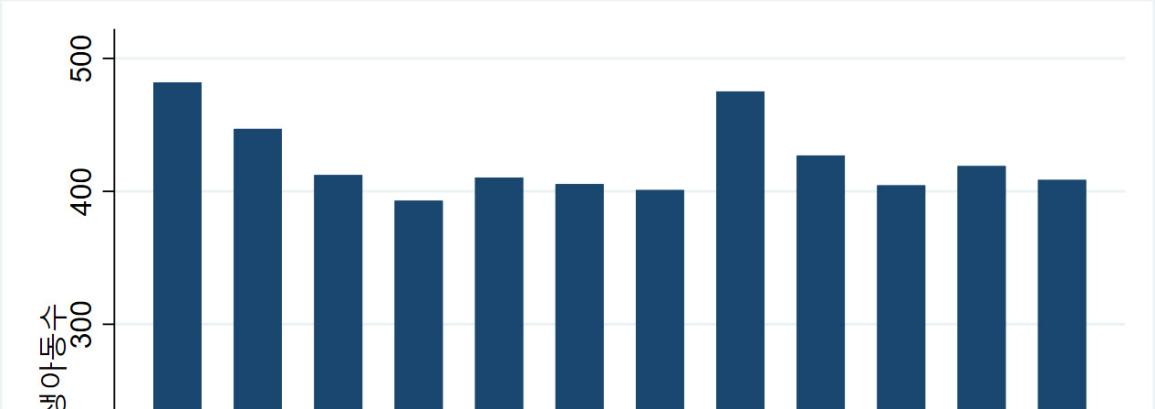

막대 그래프가 포함된 이미지로, 300에서 500 사이의 데이터를 나타내고 있으며, 여러 항목의 값이 비교되고 있습니다.
figure-12-2.jpg


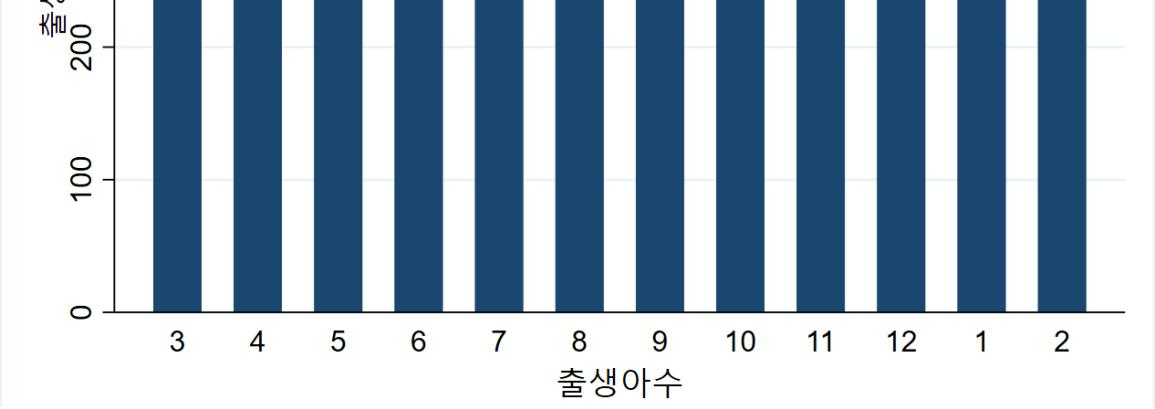

출생아 수를 나타내는 막대그래프, x축은 출생 월(3월부터 2월까지), y축은 출생아 수로 일정한 패턴과 수치 차이를 보여줌.
figure-13-3.jpg


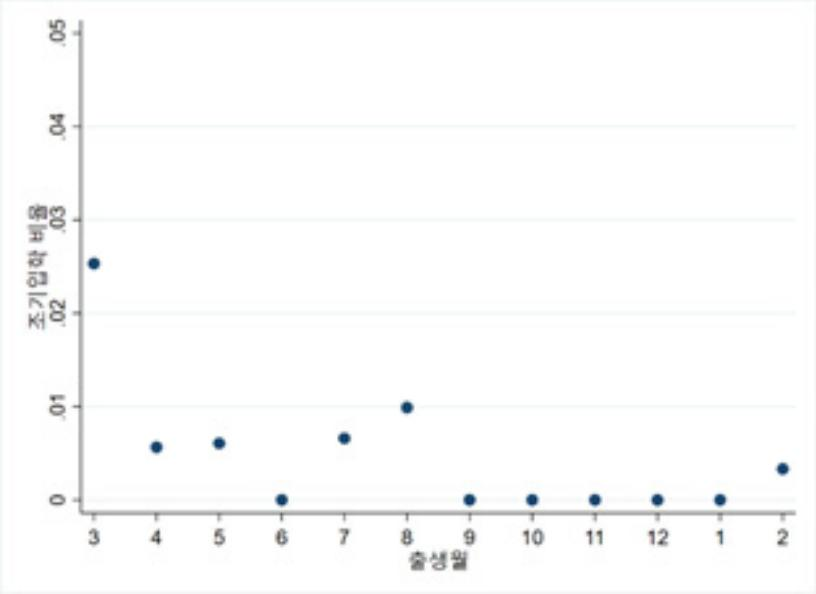

출생월과 조기입학 비용의 관계를 나타낸 산점도. x축은 출생월, y축은 조기입학 비용. 데이터 포인트는 3월부터 2월까지 나타나며 조기입학 비용은 대체로 낮은 수준이다.


In [5]:
with open(extract.DATA_DIR / 'summaries.pkl', 'rb') as f:
    summ = pickle.load(f)
print('텍스트 요약', len(summ['text_summaries']), '/ 표 요약', len(summ['table_summaries']), '/ 이미지 요약', len(summ['image_summaries']))
for p, s in list(zip(figs, summ['image_summaries']))[:3]:
    print('=' * 60); print(p.name); display(Image(filename=str(p), width=350)); print(s)

## 3단계. 검색기 + 멀티모달 체인
요약문은 벡터 DB(검색용), 원본(텍스트·표·Base64 이미지)은 docstore(전달용)에 **같은 id**로 저장합니다.

In [6]:
ret, ext = retriever.build_retriever()
model = retriever.build_model()
chain = retriever.build_multimodal_chain(ret, model)
print('멀티모달 체인 준비 완료')

색인 완료 — 벡터 DB 요약 수: 67
멀티모달 체인 준비 완료


### 질의응답 5건 (질문 / 답변 / 근거 원본 종류)

In [7]:
for i, q in enumerate(retriever.QUESTIONS, 1):
    kinds = [retriever.doc_kind(d) for d in ret.invoke(q)]
    print('=' * 70)
    print(f'[Q{i}] {q}')
    print('근거 원본:', kinds)
    print('-' * 70)
    print(chain.invoke(q))

[Q1] 출생월별 아버지의 교육년수 막대그래프에서 막대 높이는 대략 몇 년인가요?
근거 원본: ['이미지', '이미지', '텍스트/표', '이미지']
----------------------------------------------------------------------


출생월별 아버지의 교육년수 막대그래프에서 막대 높이는 대략 15년 정도로 보입니다.
[Q2] 출생월별 출생아 수 막대그래프에서 막대가 가장 높은 출생월은 몇 월이고 대략 몇 명인가요?
근거 원본: ['이미지', '이미지', '이미지', '이미지']
----------------------------------------------------------------------


출생월별 출생아 수 막대그래프에서 막대가 가장 높은 출생월은 3월이며, 대략 200명 정도입니다.
[Q3] 4학년의 국어 성적에 대한 OLS 추정계수와 IV 추정계수는 각각 얼마인가요?
근거 원본: ['텍스트/표', '텍스트/표', '텍스트/표', '텍스트/표']
----------------------------------------------------------------------


4학년의 국어 성적에 대한 OLS 추정계수는 0.172***이고, IV 추정계수는 0.236***입니다.
[Q4] 표본의 평균 실제 취학나이와 의무 취학나이, 형제 수 평균은 얼마인가요?
근거 원본: ['텍스트/표', '텍스트/표', '이미지', '텍스트/표']
----------------------------------------------------------------------


표본의 평균 실제 취학 나이는 6.6세, 의무 취학 나이는 6.52세입니다. 표본에 속한 학생의 학부모의 평균 자녀 수는 1.94명입니다.
[Q5] 이 연구는 취학 나이의 내생성 문제를 어떻게 해결했고, 어떤 결론을 얻었나요?
근거 원본: ['텍스트/표', '텍스트/표', '텍스트/표', '텍스트/표']
----------------------------------------------------------------------


이 연구는 취학 나이의 내생성 문제를 해결하기 위해 도구변수 추정법을 사용하였습니다. 구체적으로, 초·중등 교육법에 의해 규정된 취학 시기와 아동의 출생일에 의해 결정되는 의무 취학 나이를 도구변수로 활용하였습니다. 이를 통해 취학 나이가 학업성취도에 미치는 인과적인 영향을 추정하였으며, 도구변수의 완전한 외생성 조건을 완화하는 강건성 분석도 수행하였습니다.

결론적으로, 이 연구는 의무 취학 나이가 어린 아동을 둔 학부모들의 우려가 타당하다는 것을 보여주었습니다. 학부모들은 자녀의 취학 나이에 대한 유불리를 고려하여 실제로 취학 시기와 출생 시기를 선택하고 있으며, 이는 저출산·고령화에 대한 대응과 아동 교육에 대한 국가 책임 강화의 일환으로 여러 정부에서 취학연령 하향 조정 논의와 시도가 이어지고 있음을 시사합니다. 또한, 취학 나이의 효과가 고등학교에 이르기까지 지속되며, 이는 학생들의 학습에 부정적인 영향을 미칠 가능성을 배제할 수 없음을 강조하고 있습니다.


## Before / After 비교
같은 질문·같은 모델·같은 지시문. **이미지·표를 뺀 것 말고는 조건이 동일**합니다.

In [8]:
text_chain = retriever.build_text_only_chain(ext['texts_2k_token'], model)
q = retriever.COMPARE_QUERY
print('=' * 70); print('Q:', q); print('=' * 70)
print(); print('[BEFORE] 텍스트 전용 RAG'); print('-' * 70); print(text_chain.invoke(q))
print(); print('[AFTER] 멀티모달 RAG'); print('-' * 70); print(chain.invoke(q))

Q: 출생월별 아버지의 교육년수 막대그래프에서 막대 높이는 대략 몇 년인가요?

[BEFORE] 텍스트 전용 RAG
----------------------------------------------------------------------


자료에 출생월별 아버지의 교육년수에 대한 구체적인 막대 높이는 언급되어 있지 않으므로, 대략 몇 년인지 알 수 없습니다.

[AFTER] 멀티모달 RAG
----------------------------------------------------------------------


출생월별 아버지의 교육년수 막대그래프에서 막대 높이는 대략 15년 정도로 보입니다.
